In [ ]:
import numpy as np
import pandas as pd
import sys, os
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import pairwise_distances
import warnings
warnings.filterwarnings('ignore')

sys.path.append('../')
from fingerprint_analysis.calc_fps_rm import *
from local_data_utils.local_utils import plot_projection_grid_seaborn, plot_2d

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### **Loading embedding datasets**

In [11]:
names_list = ['fp', 'bert', 'evsmi', 'hvsmi', 'evslfi']
names_dict = {'fp':'Morgan_FP', 'bert':'Chemberta-2', 'evsmi': 'VAE + SMILES', 'hvsmi': fr'S-VAE + SMILES', 'evslfi':'VAE + SELFIES'}
path_init = '../results/drug_props_with_embeds_{NAME}.csv'

dfs_dict = {}
latent_dict = {}
props_dict = {}
for name in names_list:
    path_temp = path_init.format(NAME=name)
    _df = pd.read_csv(path_temp)
    dfs_dict['name'] = _df
    z = _df[[x for x in _df.columns if 'dim' in x]]
    props = _df[[x for x in _df.columns if 'dim' not in x]]

    latent_dict[name] = z.values
    props_dict[name] = props

In [12]:
from tqdm import tqdm

df_ = latent_dict['fp']
matrix = np.zeros((len(df_), len(df_)))

for i in tqdm(range(len(df_))):
    for j in range(len(df_)):
        if i<j:
            fp1 = df_[i]
            fp2 = df_[j]
            a, b, c, d = get_abcd(array_1=fp1, array_2=fp2)
            sim, dis = compute_similarity_distance_metrics(a, b, c, d)

            matrix[i, j] = sim['Tanimoto']

matrix

  0%|          | 4/1089 [00:00<01:15, 14.45it/s]

100%|██████████| 1089/1089 [00:38<00:00, 28.30it/s] 


array([[0.        , 0.1       , 0.046875  , ..., 0.09210526, 0.07352941,
        0.10126582],
       [0.        , 0.        , 0.10144928, ..., 0.10843373, 0.10810811,
        0.09090909],
       [0.        , 0.        , 0.        , ..., 0.09090909, 0.08695652,
        0.03225806],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.1       ,
        0.08108108],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.09375   ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])

In [13]:
# def mat2vec(matrix):
#     array = []
#     for i in range(matrix.shape[0]):
#         for j in range(matrix.shape[0]):
#             if i<j:
#                array.append(matrix[i, j]) 
#     return np.array(array)

In [14]:
latent_dict['evslfi'].shape

(1089, 300)

#### **Analyzing the preservation of molecular structural similarity in embedding space**

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import spearmanr, pearsonr, kendalltau

matrix_vec = matrix[np.triu_indices_from(matrix, k=1)]
all_pairwise_dist = {'fp':matrix_vec}

names_list = ['bert', 'evslfi', 'evsmi', 'hvsmi']
df = pd.DataFrame(index=names_list, columns=['Pearson', 'Spearman', 'Keldall'], dtype=float)
for name in names_list:
    dist = cosine_similarity(latent_dict[name])
    dist_vec = dist[np.triu_indices_from(dist, k=1)]
    all_pairwise_dist[name] = dist_vec
    spr, _ = spearmanr(dist_vec, matrix_vec)
    prs, _ = pearsonr(dist_vec, matrix_vec)
    kdt, _ = kendalltau(dist_vec, matrix_vec)
    df.loc[name, 'Pearson'] = prs
    df.loc[name, 'Spearman'] = spr
    df.loc[name, 'Keldall'] = kdt

df = df.round(2)
df

,Pearson,Spearman,Keldall
bert,0.47,0.55,0.38
evslfi,0.18,0.14,0.10
evsmi,0.23,0.19,0.13
hvsmi,0.21,0.19,0.13


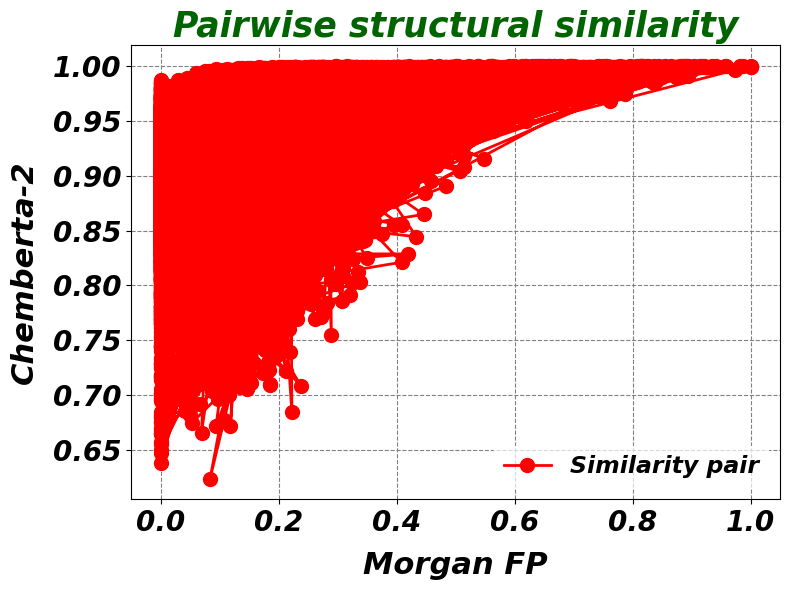

In [16]:
# props_dict[name].columns
matrices = {name:np.array([all_pairwise_dist['fp'].tolist(), all_pairwise_dist[name].tolist()]).T for name in names_list}
matrices.pop('fp')
matrices

for name in names_list:
    if name != 'fp':
        plot_2d(matrices=[matrices[name]], 
                plot_scatter=False,
                title = 'Pairwise structural similarity',
                scatter_labels = [f'Similarity pair'],
                fig_size=(8, 6),
                x_label='Morgan FP',
                y_label=names_dict[name],
                # title_fontsize=2,
                # linewidth=0.5,
                )
        break

#### **Calculating the correlations between the distances in embedding space w.r.t molecular descriptors**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings('ignore')

prop_list = ['LogP', 'Molecular Mass', 'NumHDonors', 'NumHAcceptor', 'TPSA', 'NumRotatableBonds']
df = pd.DataFrame(index=names_list, columns=prop_list, dtype=float)

for name in names_list:
    if name == 'fp':
        embed_dist = pairwise_distances(latent_dict[name], metric='jaccard')
    else:
        embed_dist = pairwise_distances(latent_dict[name])

    embed_dist_vec = embed_dist[np.triu_indices_from(embed_dist, k=1)]
    for prop in prop_list:
        prop_dist = pairwise_distances(props_dict[name][prop].values.reshape(-1, 1))
        prop_dist_vec = prop_dist[np.triu_indices_from(prop_dist, k=1)]
        spr_prop, _ = spearmanr(embed_dist_vec, prop_dist_vec)
        df.loc[name, prop] = spr_prop

names_list = ['fp', 'evslfi', 'evsmi', 'hvsmi', 'bert']
df = df.round(2).T[names_list]
df

,fp,evslfi,evsmi,hvsmi,bert
LogP,0.11,0.21,0.20,0.12,0.17
Molecular Mass,0.32,0.60,0.58,0.70,0.18
NumHDonors,0.21,0.27,0.26,0.17,0.10
NumHAcceptor,0.38,0.48,0.45,0.38,0.13
TPSA,0.32,0.40,0.40,0.30,0.17
NumRotatableBonds,0.21,0.25,0.30,0.18,0.05


#### **Calculating the Correlation between the pairwise distances of all the embedding methods**

In [ ]:
df = pd.DataFrame(index=names_list, columns=names_list, dtype=float)
dist_dict = {}

for name in names_list:
    metric = 'jaccard' if name == 'fp' else 'euclidean'
    dist = pairwise_distances(latent_dict[name], metric=metric)
    dist_dict[name] = dist[np.triu_indices_from(dist, k=1)]

names_list = ['fp', 'evslfi', 'evsmi', 'hvsmi', 'bert']
for name1 in names_list:
    for name2 in names_list:
        spr_prop, _ = spearmanr(dist_dict[name1], dist_dict[name2])
        df.loc[name1, name2] = spr_prop

df = df.round(2)
df = df[names_list]
df

,fp,evslfi,evsmi,hvsmi,bert
fp,1.00,0.08,0.10,0.19,0.54
evslfi,0.08,1.00,0.89,0.64,0.07
evsmi,0.10,0.89,1.00,0.62,0.15
hvsmi,0.19,0.64,0.62,1.00,0.23
bert,0.54,0.07,0.15,0.23,1.00


#### **Performance comparison among downstream tasks**

In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, root_mean_squared_error

names_list = ['fp', 'evslfi', 'evsmi', 'hvsmi', 'bert']
prop_list = ['Molecular Mass', 'LogP', 'TPSA', 'NumHDonors', 'NumHAcceptor', 'NumRotatableBonds']
results = {}
for prop_name in prop_list:
    for repr_method in names_list:

        X = latent_dict[repr_method]
        y = props_dict[repr_method][prop_name]
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, shuffle=True)

        rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
        svm_model = make_pipeline(StandardScaler(), SVR())

        rf_model.fit(X_train, y_train)
        svm_model.fit(X_train, y_train)

        y_pred_rf = rf_model.predict(X_test)
        y_pred_svm = svm_model.predict(X_test)

        results.setdefault((prop_name, 'RF'), {})[repr_method] = (r2_score(y_test, y_pred_rf))
        results.setdefault((prop_name, 'SVR'), {})[repr_method] = (r2_score(y_test, y_pred_svm))

df = pd.DataFrame.from_dict(results, orient='index')
df.index = pd.MultiIndex.from_tuples(df.index, names=['Property', 'Regressor'])
df = df.round(2)

df

fp  evslfi  evsmi  hvsmi  bert
Property          Regressor                                  
Molecular Mass    RF         0.66    0.81   0.83   0.86  0.88
                  SVR        0.10    0.20   0.15   0.35  0.19
LogP              RF         0.64    0.40   0.49   0.25  0.84
                  SVR        0.42    0.48   0.55   0.22  0.78
TPSA              RF         0.81    0.69   0.74   0.64  0.89
                  SVR        0.11    0.24   0.21   0.30  0.45
NumHDonors        RF         0.79    0.51   0.50   0.42  0.69
                  SVR        0.40    0.40   0.44   0.39  0.65
NumHAcceptor      RF         0.85    0.78   0.78   0.71  0.90
                  SVR        0.55    0.69   0.66   0.66  0.91
NumRotatableBonds RF         0.56    0.25   0.34   0.49  0.68
                  SVR        0.35    0.37   0.45   0.51  0.55